# Quick start

In [87]:
import numpy as np
import pandas as pd
import matplotlib as mpl
from anndata import AnnData
import matplotlib.pyplot as plt
import spatialdata as sd
from spatialdata.models import TableModel
import spatialdata_plot
from matplotlib.patches import Patch
from typing import Literal

assert spatialdata_plot.__version__ == "0.2.13"

_AX_BG_COLOR = "white"

In [88]:
## Load provided SpatialData object
sdata = sd.read_zarr("../data/ST8059048.zarr")

In [89]:
data_table = sdata['table']
bulks = data_table.to_df()
import matplotlib.pyplot as plt
# total counts per column (gene) and per row (spot)
counts_per_row = bulks.sum(axis=1)






In [90]:
estimations = pd.read_csv("../data/fig5/rectangle_ST8059048_estimations-qs.csv", index_col=0)
estimations

,Astro_AMY,Astro_HPC,Astro_HYPO,Astro_THAL,Astro_WM,Ext_Amy,Ext_ClauPyr,Ext_Hpc,Ext_L23,Ext_L25,...,Inh_Lamp5,Inh_Meis2,Inh_Pvalb,Inh_Sst,Inh_Vip,Micro,Nb,OPC,Oligo,Unknown
AAACAAGTATCTCCCA-1,1.847451e-06,2.316450e-01,0.033336,3.974039e-07,0.104399,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,...,0.007490,0.000000,0.000000,0.000000e+00,0.000000,0.044057,0.000000e+00,0.000000e+00,0.153705,0.255256
AAACACCAATAACTGC-1,3.975749e-07,2.703082e-01,0.001302,0.000000e+00,0.472718,6.281386e-05,0.000000e+00,2.709018e-02,0.011626,0.000000e+00,...,0.003257,0.001202,0.000000,0.000000e+00,0.008241,0.021027,0.000000e+00,0.000000e+00,0.161306,0.000000
AAACAGAGCGACTCCT-1,1.357305e-08,4.388573e-02,0.000682,0.000000e+00,0.227624,0.000000e+00,1.854498e-04,0.000000e+00,0.181612,2.403983e-04,...,0.005465,0.000000,0.000000,4.656285e-05,0.000000,0.051620,5.074536e-03,0.000000e+00,0.102938,0.318373
AAACAGCTTTCAGAAG-1,0.000000e+00,2.262004e-01,0.001133,0.000000e+00,0.296871,0.000000e+00,2.466991e-03,4.102842e-09,0.152400,2.011173e-02,...,0.006323,0.000000,0.000143,1.164500e-09,0.000339,0.078029,7.944136e-03,9.754559e-09,0.026564,0.125466
AAACAGGGTCTATATT-1,0.000000e+00,1.036371e-07,0.001795,0.000000e+00,0.471020,0.000000e+00,1.194871e-03,0.000000e+00,0.272136,0.000000e+00,...,0.000000,0.000000,0.000000,6.850711e-05,0.000000,0.025424,8.743365e-03,1.310225e-02,0.012611,0.192516
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGTTCAGTGTGCTAC-1,0.000000e+00,4.837199e-02,0.000129,0.000000e+00,0.048654,4.498547e-07,2.289640e-03,3.983585e-01,0.000000,2.384808e-04,...,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.007901,4.643584e-07,0.000000e+00,0.043703,0.399862
TTGTTGTGTGTCAAGA-1,1.006596e-06,1.144218e-01,0.000368,1.251876e-01,0.145707,0.000000e+00,0.000000e+00,0.000000e+00,0.025955,2.244111e-05,...,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.005508,0.000000e+00,7.719454e-07,0.293053,0.225351
TTGTTTCACATCCAGG-1,0.000000e+00,1.033298e-01,0.000453,0.000000e+00,0.175832,5.642204e-02,2.160742e-08,1.338483e-04,0.184861,3.183745e-08,...,0.020715,0.000000,0.000000,8.207590e-02,0.007280,0.048402,1.380280e-03,1.078641e-08,0.037212,0.263874
TTGTTTCATTAGTCTA-1,0.000000e+00,0.000000e+00,0.005156,0.000000e+00,0.303378,2.927280e-03,1.848254e-03,0.000000e+00,0.000000,0.000000e+00,...,0.025874,0.000000,0.000027,7.012753e-02,0.006965,0.019607,3.557694e-04,2.934566e-04,0.066801,0.397234


In [91]:
# remove spots with count lower
low_count_spots = counts_per_row[counts_per_row < 500].index
estimations = estimations.drop(index=low_count_spots)
estimations

,Astro_AMY,Astro_HPC,Astro_HYPO,Astro_THAL,Astro_WM,Ext_Amy,Ext_ClauPyr,Ext_Hpc,Ext_L23,Ext_L25,...,Inh_Lamp5,Inh_Meis2,Inh_Pvalb,Inh_Sst,Inh_Vip,Micro,Nb,OPC,Oligo,Unknown
AAACAAGTATCTCCCA-1,1.847451e-06,2.316450e-01,0.033336,3.974039e-07,0.104399,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,...,0.007490,0.000000,0.000000,0.000000e+00,0.000000,0.044057,0.000000e+00,0.000000e+00,0.153705,0.255256
AAACACCAATAACTGC-1,3.975749e-07,2.703082e-01,0.001302,0.000000e+00,0.472718,6.281386e-05,0.000000e+00,2.709018e-02,0.011626,0.000000e+00,...,0.003257,0.001202,0.000000,0.000000e+00,0.008241,0.021027,0.000000e+00,0.000000e+00,0.161306,0.000000
AAACAGAGCGACTCCT-1,1.357305e-08,4.388573e-02,0.000682,0.000000e+00,0.227624,0.000000e+00,1.854498e-04,0.000000e+00,0.181612,2.403983e-04,...,0.005465,0.000000,0.000000,4.656285e-05,0.000000,0.051620,5.074536e-03,0.000000e+00,0.102938,0.318373
AAACAGCTTTCAGAAG-1,0.000000e+00,2.262004e-01,0.001133,0.000000e+00,0.296871,0.000000e+00,2.466991e-03,4.102842e-09,0.152400,2.011173e-02,...,0.006323,0.000000,0.000143,1.164500e-09,0.000339,0.078029,7.944136e-03,9.754559e-09,0.026564,0.125466
AAACAGGGTCTATATT-1,0.000000e+00,1.036371e-07,0.001795,0.000000e+00,0.471020,0.000000e+00,1.194871e-03,0.000000e+00,0.272136,0.000000e+00,...,0.000000,0.000000,0.000000,6.850711e-05,0.000000,0.025424,8.743365e-03,1.310225e-02,0.012611,0.192516
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGTTCAGTGTGCTAC-1,0.000000e+00,4.837199e-02,0.000129,0.000000e+00,0.048654,4.498547e-07,2.289640e-03,3.983585e-01,0.000000,2.384808e-04,...,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.007901,4.643584e-07,0.000000e+00,0.043703,0.399862
TTGTTGTGTGTCAAGA-1,1.006596e-06,1.144218e-01,0.000368,1.251876e-01,0.145707,0.000000e+00,0.000000e+00,0.000000e+00,0.025955,2.244111e-05,...,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.005508,0.000000e+00,7.719454e-07,0.293053,0.225351
TTGTTTCACATCCAGG-1,0.000000e+00,1.033298e-01,0.000453,0.000000e+00,0.175832,5.642204e-02,2.160742e-08,1.338483e-04,0.184861,3.183745e-08,...,0.020715,0.000000,0.000000,8.207590e-02,0.007280,0.048402,1.380280e-03,1.078641e-08,0.037212,0.263874
TTGTTTCATTAGTCTA-1,0.000000e+00,0.000000e+00,0.005156,0.000000e+00,0.303378,2.927280e-03,1.848254e-03,0.000000e+00,0.000000,0.000000e+00,...,0.025874,0.000000,0.000027,7.012753e-02,0.006965,0.019607,3.557694e-04,2.934566e-04,0.066801,0.397234


In [92]:
# Check available cell types
print("Available columns in estimations:")
print(estimations.columns.tolist())
print("\nLooking for Pir-related columns:")
pir_cols = [col for col in estimations.columns if 'Pir' in col or 'pir' in col.lower()]
print(pir_cols)


Available columns in estimations:
['Astro_AMY', 'Astro_HPC', 'Astro_HYPO', 'Astro_THAL', 'Astro_WM', 'Ext_Amy', 'Ext_ClauPyr', 'Ext_Hpc', 'Ext_L23', 'Ext_L25', 'Ext_L5', 'Ext_L56', 'Ext_L6', 'Ext_L6B', 'Ext_Pir', 'Ext_Thal', 'Inh', 'Inh_Lamp5', 'Inh_Meis2', 'Inh_Pvalb', 'Inh_Sst', 'Inh_Vip', 'Micro', 'Nb', 'OPC', 'Oligo', 'Unknown']

Looking for Pir-related columns:
['Ext_Pir']


In [93]:
def _get_most_likely_cell_type(rectangle_results, ):
    """Takes in a DataFrame representing the results of Rectangle deconvolution and returns
    a DataFrame with the most likely cell type for each observation. For each observation, the most likely cell type is selected and the likelihood of
    the others is set to 0. Then, the cell types are sorted by abundance.
    """
    # Select only numeric columns to avoid string comparison errors
    numeric_cols = rectangle_results.select_dtypes(include=[np.number]).columns.tolist()

    if not numeric_cols:
        raise ValueError("No numeric columns found in rectangle_results")

    arr = rectangle_results[numeric_cols].to_numpy(copy=False)
    idx = arr.argmax(axis=1)
    out = np.zeros_like(arr)
    rows = np.arange(arr.shape[0])
    out[rows, idx] = arr[rows, idx]

    out_df = rectangle_results.copy()
    out_df.loc[:, numeric_cols] = out

    # Sort by abundance (count of non-zero values)
    celltype_abundance = (out_df[numeric_cols] > 0).sum(axis=0)
    celltype_abundance = celltype_abundance.sort_values(ascending=False)

    return out_df.loc[:, celltype_abundance.index.values.tolist()]


def add_rectangle_results_to_spatialdata(
    sdata,
    estimations: pd.DataFrame,
    celltypes: list,
    *,
    table_name: str = "rectangle_results",
    region_name: str = "ST8059048",
    source_table: str = "table",
):
    """Process Rectangle deconvolution estimations and add them to a SpatialData object.

    Parameters
    ----------
    sdata
        The SpatialData object to add results to
    estimations
        DataFrame containing Rectangle deconvolution estimations (observations as index,
        cell types as columns)
    celltypes
        List of cell type column names to include in the analysis
    table_name
        Name of the table to store results in sdata.tables. Default: "rectangle_results"
    region_name
        Name of the region for spatialdata attributes. Default: "ST8059048"
    source_table
        Name of the source table in sdata.tables to merge spot_id from. Default: "table"

    Returns
    -------
    None
        Modifies sdata in place by adding the processed table to sdata.tables[table_name]

    """
    # Process the estimations
    cleaned_results = _get_most_likely_cell_type(estimations[celltypes])

    # Create AnnData object
    table_data = AnnData(cleaned_results)
    adata_for_sdata = TableModel.parse(table_data)

    # Clean up the spot_id by filtering out bad indices
    spot_id_df = adata_for_sdata.obs.merge(
        sdata.tables[source_table].obs, left_index=True, right_index=True, how="left"
    )

    # Filter out observations with invalid spot_id
    bad_mask = np.isnan(spot_id_df["spot_id"].values)
    good_idx = spot_id_df[~bad_mask].index.values

    # Filter the AnnData object to only include good indices
    adata_for_sdata = adata_for_sdata[good_idx, :].copy()

    # Set up spatialdata attributes
    adata_for_sdata.uns["spatialdata_attrs"] = {
        "region": region_name,
        "region_key": "region",
        "instance_key": "spot_id",
    }

    # Add region and spot_id to observations
    adata_for_sdata.obs["region"] = pd.Categorical([region_name] * len(adata_for_sdata))
    adata_for_sdata.obs["spot_id"] = spot_id_df.loc[good_idx, "spot_id"].values.astype(int)

    # Add to spatialdata object
    sdata.tables[table_name] = adata_for_sdata

    # Sanitize, not sure why there are NaNs
    sdata.tables[table_name].X = sdata.tables[table_name].to_df().fillna(0).values

celltypes_to_viz = [
    "Ext_L23",
    "Ext_L25",
    "Ext_L5",
    "Ext_L56",
    "Ext_L6B"
]

add_rectangle_results_to_spatialdata(
    sdata=sdata,
    estimations=estimations,
    celltypes=celltypes_to_viz,
    table_name="rectangle_results",
    region_name="ST8059048",
    source_table="table"
)

sdata.tables["rectangle_results"].to_df()

,Ext_L23,Ext_L56,Ext_L25,Ext_L6B,Ext_L5
AAACAAGTATCTCCCA-1,0.000000,0.000095,0.0,0.0,0.0
AAACACCAATAACTGC-1,0.011626,0.000000,0.0,0.0,0.0
AAACAGAGCGACTCCT-1,0.181612,0.000000,0.0,0.0,0.0
AAACAGCTTTCAGAAG-1,0.152400,0.000000,0.0,0.0,0.0
AAACAGGGTCTATATT-1,0.272136,0.000000,0.0,0.0,0.0
...,...,...,...,...,...
TTGTTCAGTGTGCTAC-1,0.000000,0.032962,0.0,0.0,0.0
TTGTTGTGTGTCAAGA-1,0.025955,0.000000,0.0,0.0,0.0
TTGTTTCACATCCAGG-1,0.184861,0.000000,0.0,0.0,0.0
TTGTTTCATTAGTCTA-1,0.000000,0.005886,0.0,0.0,0.0


In [94]:


celltypes = [
    "Ext_L23",
    "Ext_L25",
    "Ext_L5",
    "Ext_L56",
    "Ext_L6B"
]
colors = [
    "Purple",
    "Blue",
    "Green",
    "Yellow",
    "Orange"
]

celltype_color_map = dict(zip(celltypes, colors))
celltype_color_map

{'Ext_L23': 'Purple',
 'Ext_L25': 'Blue',
 'Ext_L5': 'Green',
 'Ext_L56': 'Yellow',
 'Ext_L6B': 'Orange'}

In [95]:
def transparent_sequential_cmap(
    color: str, n: int = 256, bg: Literal["white", "black"] = "white", name: str | None = None
) -> mpl.colors.ListedColormap:
    """Create a cmap from `color` to `bg` where value 0 is fully transparent."""
    rgb_target = np.array(mpl.colors.to_rgb(color), dtype=float)
    if bg == "white":
        bg_color = np.ones(3, dtype=float)
    elif bg == "black":
        bg_color = np.zeros(3, dtype=float)
    else:
        raise ValueError(f"bg must be 'white' or 'black', got {bg!r}")

    t = np.linspace(0.0, 1.0, n)  # 0 → 1 along the colormap
    rgb = (1.0 - t)[:, None] * bg_color[None, :] + t[:, None] * rgb_target[None, :]  # white → color
    alpha = t  # 0 at start, 1 at end

    rgba = np.concatenate([rgb, alpha[:, None]], axis=1)
    return mpl.colors.ListedColormap(rgba, name or f"{color}_transparent_seq")



INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata_plot/pl/basic.py:962: UserWarning: Converting copy of 'is_bad' column to categorical dtype for categorical plotting. Consider converting before plotting.
  _render_sh

INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


...

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


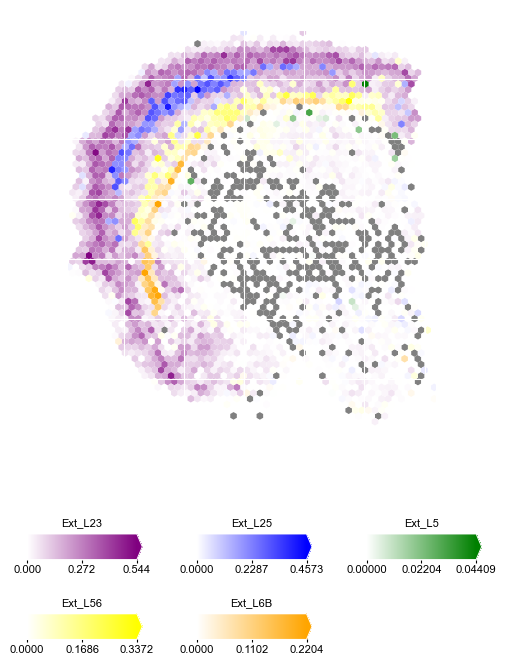

In [96]:
import matplotlib.pyplot as plt
from matplotlib.colorbar import ColorbarBase
from matplotlib.colors import Normalize, Colormap


def add_celltype_colorbar(
    ax: plt.Axes,
    values: np.ndarray,
    cmap: Colormap,
    name: str,
    *,
    bg: str = "white",
    text_color: str = "black",
    n_ticks: int = 3,
    bar_y: float = 0.12,
    bar_h: float = 0.45,
    outline_color: str = "white",
    outline_width: float = 0.75,
) -> None:
    vals = np.asarray(values, float)
    vals = vals[~np.isnan(vals)]
    if vals.size == 0:
        vmin, vmax = 0.0, 1.0
    else:
        vmin, vmax = float(vals.min()), float(vals.max())
        if vmin == vmax:
            vmin -= 0.5
            vmax += 0.5

    # make an opaque version of the cmap (no fade-to-white effect)
    base = cmap(np.linspace(0.0, 1.0, 256))
    base[:, 3] = 1.0  # alpha = 1
    cmap_opaque = mpl.colors.ListedColormap(base, name=f"{cmap.name}_opaque")

    # outer slot
    ax.set_facecolor(bg)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)

    # inner bar
    bar_ax = ax.inset_axes([0.02, bar_y, 0.96, bar_h])
    bar_ax.set_facecolor(bg)

    cbar = ColorbarBase(
        bar_ax,
        cmap=cmap_opaque,
        norm=Normalize(vmin=vmin, vmax=vmax),
        orientation="horizontal",
        extend="both",
        extendfrac=0.05,
    )

    # ticks
    ticks = np.linspace(vmin, vmax, n_ticks)
    cbar.set_ticks(ticks)
    cbar.ax.tick_params(colors=text_color, labelsize=8, length=2, pad=2)

    # white outline
    for spine in bar_ax.spines.values():
        spine.set_edgecolor(outline_color)
        spine.set_linewidth(outline_width)

    # title
    title_to_cmap_pad = 0.10
    ax.text(
        0.5,
        bar_y + bar_h + title_to_cmap_pad,
        name,
        ha="center",
        va="bottom",
        color=text_color,
        fontsize=8,
        transform=ax.transAxes,
    )

# 1) Set up the figure and layout
fig = plt.figure(figsize=(6, 8), facecolor="white")

# top: 3/4, bottom: 1/4
gs = fig.add_gridspec(
    nrows=2,
    ncols=1,
    height_ratios=[3, 1],
    hspace=0.25,
)
# bottom area: 2 rows × 3 cols
bottom_gs = gs[1].subgridspec(
    nrows=2,
    ncols=3,
    wspace=0.35,
    hspace=0.4,
)
bottom_axs = bottom_gs.subplots()
bottom_axs = bottom_axs.flatten()

# 2) Define celltypes and colors and prepare the SpatialData object
celltypes_to_viz = [
    "Ext_L23",
    "Ext_L25",
    "Ext_L5",
    "Ext_L56",
    "Ext_L6B"
]

colors = [
    "Purple",
    "Blue",
    "Green",
    "Yellow",
    "Orange"
]
celltype_color_map = dict(zip(celltypes_to_viz, colors))

add_rectangle_results_to_spatialdata(
    sdata=sdata,
    estimations=estimations,
    celltypes=celltypes_to_viz,
    table_name="rectangle_results",
    region_name="ST8059048",
    source_table="table",
)

# Define obs that have 0 for all celltypes as bad so we can color them
sdata["rectangle_results"].obs["is_bad"] = sdata["rectangle_results"].to_df().sum(axis=1) == 0
sdata["rectangle_results"].obs["is_bad"] = sdata["rectangle_results"].obs["is_bad"].astype(str)

# 3) Draw the hex plot
top_ax = fig.add_subplot(gs[0])

(
    sdata.pl.render_shapes(
        color="is_bad",
        groups=["True", "False"],
        palette=["gray", "white"],
        shape="visium_hex",
        table_name="rectangle_results",
    ).pl.show("ST8059048", ax=top_ax, legend_loc=None)
)

for celltype, color in celltype_color_map.items():
    cmap = transparent_sequential_cmap(color, n=256, name=f"{celltype}_transparent_seq", bg=_AX_BG_COLOR)
    (
        sdata.pl.render_shapes(
            color=celltype,
            cmap=cmap,
            shape="visium_hex",
            table_name="rectangle_results",
        ).pl.show("ST8059048", ax=top_ax, colorbar=False)
    )

top_ax.set_facecolor("white")

# 4) Draw the colorbars
for i, (celltype, color) in enumerate(celltype_color_map.items()):
    cmap = transparent_sequential_cmap(color, n=256, name=f"{celltype}_transparent_seq", bg="white")
    add_celltype_colorbar(
        bottom_axs[i],
        sdata.tables["rectangle_results"].to_df()[celltype],
        cmap,
        celltype,
    )

# Hide the unused 6th subplot
bottom_axs[5].set_visible(False)

# Ensure that used colorbars have white background
for ax in bottom_axs[:5]:
    ax.set_facecolor("white")

plt.show()


In [97]:
sdata["rectangle_results"].to_df().sum(axis=1)

AAACAAGTATCTCCCA-1    0.000095
AAACACCAATAACTGC-1    0.011626
AAACAGAGCGACTCCT-1    0.181612
AAACAGCTTTCAGAAG-1    0.152400
AAACAGGGTCTATATT-1    0.272136
                        ...   
TTGTTCAGTGTGCTAC-1    0.032962
TTGTTGTGTGTCAAGA-1    0.025955
TTGTTTCACATCCAGG-1    0.184861
TTGTTTCATTAGTCTA-1    0.005886
TTGTTTCCATACAACT-1    0.109476
Length: 2957, dtype: float64

In [98]:
import matplotlib.pyplot as plt
from matplotlib.colorbar import ColorbarBase
from matplotlib.colors import Normalize, Colormap


def add_celltype_colorbar(
    ax: plt.Axes,
    values: np.ndarray,
    cmap: Colormap,
    name: str,
    *,
    bg: str = "white",
    text_color: str = "black",
    n_ticks: int = 3,
    bar_y: float = 0.12,
    bar_h: float = 0.45,
    outline_color: str = "white",
    outline_width: float = 0.75,
) -> None:
    vals = np.asarray(values, float)
    vals = vals[~np.isnan(vals)]
    if vals.size == 0:
        vmin, vmax = 0.0, 1.0
    else:
        vmin, vmax = float(vals.min()), float(vals.max())
        if vmin == vmax:
            vmin -= 0.5
            vmax += 0.5

    # make an opaque version of the cmap (no fade-to-white effect)
    base = cmap(np.linspace(0.0, 1.0, 256))
    base[:, 3] = 1.0  # alpha = 1
    cmap_opaque = mpl.colors.ListedColormap(base, name=f"{cmap.name}_opaque")

    # outer slot
    ax.set_facecolor(bg)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)

    # inner bar
    bar_ax = ax.inset_axes([0.02, bar_y, 0.96, bar_h])
    bar_ax.set_facecolor(bg)

    cbar = ColorbarBase(
        bar_ax,
        cmap=cmap_opaque,
        norm=Normalize(vmin=vmin, vmax=vmax),
        orientation="horizontal",
        extend="both",
        extendfrac=0.05,
    )

    # ticks
    ticks = np.linspace(vmin, vmax, n_ticks)
    cbar.set_ticks(ticks)
    cbar.set_ticklabels([f"{t:.3f}" for t in ticks])
    cbar.ax.tick_params(colors=text_color, labelsize=8, length=2, pad=2)

    # white outline
    for spine in bar_ax.spines.values():
        spine.set_edgecolor(outline_color)
        spine.set_linewidth(outline_width)

    # title
    title_to_cmap_pad = 0.10
    ax.text(
        0.5,
        bar_y + bar_h + title_to_cmap_pad,
        name,
        ha="center",
        va="bottom",
        color=text_color,
        fontsize=8,
        transform=ax.transAxes,
    )

# 1) Set up the figure and layout
gs = fig.add_gridspec(
    nrows=2,
    ncols=1,
    height_ratios=[3, 1],
    hspace=0.25,
)

bottom_gs = gs[1].subgridspec(
    nrows=n_rows,
    ncols=n_cols,
    wspace=0.35,
    hspace=0.4,
)
bottom_axs = bottom_gs.subplots()
bottom_axs = bottom_axs.flatten()

# 2) Define celltypes and colors and prepare the SpatialData object
# First, check what Pir-related columns exist
pir_candidates = [col for col in estimations.columns if 'pir' in col.lower()]
print(f"Pir-related columns found: {pir_candidates}")

# Define requested cell types - adjust based on what's actually in the data
requested_celltypes = [
    "Ext_L23",
    "Ext_L25",  # L35 doesn't exist in data
    "Ext_L56",
    "Ext_L6B",
    "Ext_Hpc",
    "Ext_Thal",
    "Ext_ClauPyr"
]

# Try to add Pir if it exists
if pir_candidates:
    requested_celltypes.insert(5, pir_candidates[0])  # Add first Pir variant found
    print(f"Using Pir column: {pir_candidates[0]}")
else:
    print("Warning: No Pir-related columns found in estimations data!")

# Filter to only include cell types that actually exist in the data
celltypes_to_viz = [ct for ct in requested_celltypes if ct in estimations.columns]
print(f"\nFinal cell types to visualize: {celltypes_to_viz}")

missing = [ct for ct in requested_celltypes if ct not in estimations.columns]
if missing:
    print(f"WARNING: These requested cell types are not in the data: {missing}")

colors = [
    "Purple",
    "Blue",
    "Green",
    "Yellow",
    "Orange",
    "Red",
    "Cyan",
    "Magenta"
][:len(celltypes_to_viz)]  # Only use as many colors as we have cell types

celltype_color_map = dict(zip(celltypes_to_viz, colors))

add_rectangle_results_to_spatialdata(
    sdata=sdata,
    estimations=estimations,
    celltypes=celltypes_to_viz,
    table_name="rectangle_results",
    region_name="ST8059048",
    source_table="table",
)

# 3) Draw the hex plot
top_ax = fig.add_subplot(gs[0])
for celltype, color in celltype_color_map.items():
    cmap = transparent_sequential_cmap(color, n=256, name=f"{celltype}_transparent_seq", bg="white")
    (
        sdata.pl.render_shapes(
            color=celltype,
            cmap=cmap,
            shape="visium_hex",
            table_name="rectangle_results",
        ).pl.show("ST8059048", ax=top_ax, colorbar=False)
    )

top_ax.set_facecolor("white")

# 4) Draw the colorbars
for i, (celltype, color) in enumerate(celltype_color_map.items()):
    cmap = transparent_sequential_cmap(color, n=256, name=f"{celltype}_transparent_seq", bg="white")
    add_celltype_colorbar(
        bottom_axs[i],
        sdata.tables["rectangle_results"].to_df()[celltype],
        cmap,
        celltype,
    )

# Ensure that all colorbars have white background
for ax in bottom_axs[:8]:
    ax.set_facecolor("white")

plt.show()


Pir-related columns found: ['Ext_Pir']
Using Pir column: Ext_Pir

Final cell types to visualize: ['Ext_L23', 'Ext_L25', 'Ext_L56', 'Ext_L6B', 'Ext_Hpc', 'Ext_Pir', 'Ext_Thal', 'Ext_ClauPyr']
INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


...

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata_plot/pl/basic.py:962: UserWarning: Converting copy of 'is_bad' column to categorical dtype for categorical plotting. Consider converting before plotting.
  _render_shapes(
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata_plot/pl/utils.py:872: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be cha

INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


...

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


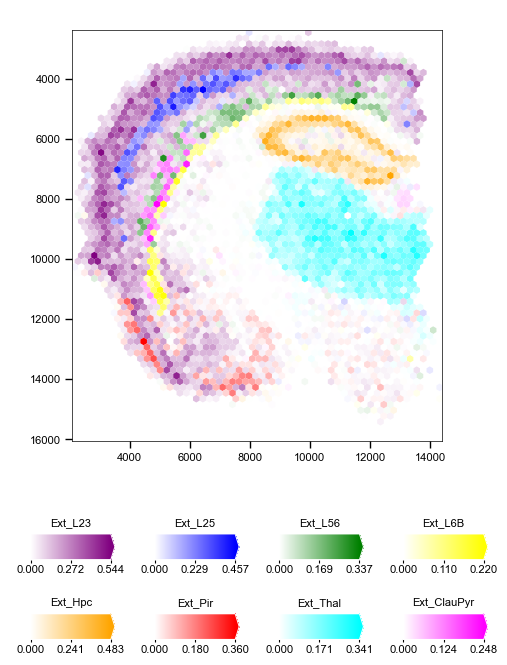

In [107]:
# Plot with highlighted spots where all cell types are 0

# 1) Set up the figure and layout
fig = plt.figure(figsize=(6, 8), facecolor="white")

# top: 3/4, bottom: 1/4
gs = fig.add_gridspec(
    nrows=2,
    ncols=1,
    height_ratios=[3, 1],
    hspace=0.25,
)
# bottom area: flexible grid based on number of cell types
n_celltypes = len(celltypes_to_viz)
n_cols = min(4, n_celltypes)
n_rows = (n_celltypes + n_cols - 1) // n_cols  # Ceiling division

bottom_gs = gs[1].subgridspec(
    nrows=n_rows,
    ncols=n_cols,
    wspace=0.35,
    hspace=0.4,
)
bottom_axs = bottom_gs.subplots()
bottom_axs = bottom_axs.flatten()


sdata["rectangle_results"].obs["is_bad"] = "False"

# 3) Draw the hex plot with bad spots highlighted
top_ax = fig.add_subplot(gs[0])

# First, draw the bad spots layer (black for spots with all zeros/tiny values, transparent for valid spots)
(
    sdata.pl.render_shapes(
        color="is_bad",
        groups=["True", "False"],
        palette=["gray", "white"],
        alpha=1.0,
        shape="visium_hex",
        table_name="rectangle_results",
    ).pl.show("ST8059048", ax=top_ax, legend_loc=None, colorbar=False)
)

# Then overlay the cell type layers
for celltype, color in celltype_color_map.items():
    cmap = transparent_sequential_cmap(color, n=256, name=f"{celltype}_transparent_seq", bg="white")
    (
        sdata.pl.render_shapes(
            color=celltype,
            cmap=cmap,
            shape="visium_hex",
            table_name="rectangle_results",
        ).pl.show("ST8059048", ax=top_ax, colorbar=False)
    )

top_ax.set_facecolor("white")

# 4) Draw the colorbars
for i, (celltype, color) in enumerate(celltype_color_map.items()):
    cmap = transparent_sequential_cmap(color, n=256, name=f"{celltype}_transparent_seq", bg="white")
    add_celltype_colorbar(
        bottom_axs[i],
        sdata.tables["rectangle_results"].to_df()[celltype],
        cmap,
        celltype,
    )

# Ensure that all colorbars have white background
for ax in bottom_axs[:len(celltypes_to_viz)]:
    ax.set_facecolor("white")

# Hide unused subplots
for ax in bottom_axs[len(celltypes_to_viz):]:
    ax.set_visible(False)

# Configure axis AFTER all plotting is done
top_ax.set_facecolor("white")

# Force draw to finalize the rendering
fig.canvas.draw_idle()

# Now configure the axis
top_ax.set_axis_on()

# Force spines to be visible
for spine in top_ax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor('black')
    spine.set_linewidth(0.5)

# Remove grid
top_ax.grid(False)

# Force the axis to show ticks
top_ax.xaxis.set_visible(True)
top_ax.yaxis.set_visible(True)

# Get current axis limits
xlim = top_ax.get_xlim()
ylim = top_ax.get_ylim()

# Explicitly set ticks
import numpy as np
from matplotlib.ticker import MultipleLocator, AutoLocator

# Try using AutoLocator first to see if matplotlib can handle it
top_ax.xaxis.set_major_locator(AutoLocator())
top_ax.yaxis.set_major_locator(AutoLocator())

# Add axis labels
top_ax.set_xlabel('X position', fontsize=10)
top_ax.set_ylabel('Y position', fontsize=10)

# Configure tick appearance - make them more visible
top_ax.tick_params(
    axis='both',
    which='major',
    labelsize=8,
    length=5,
    width=1.0,
    direction='out',
    color='black',
    labelcolor='black',
    bottom=True,
    top=False,
    left=True,
    right=False
)

# Force another draw
fig.canvas.draw_idle()

plt.show()

# save figure
fig.savefig("../figures/5b_spatial.pdf", dpi=300, bbox_inches="tight")
